In [2]:
import lancedb
import polars as pl
from scipy.spatial import distance
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np
import random

In [16]:
uri = "../../data/pokemon_db"
db = lancedb.connect(uri)

db.list_tables()

ListTablesResponse(context=None, tables=['pokemon'], page_token=None)

In [20]:
table_name = "pokemon"
table = db.open_table(table_name)
df = table.search().to_polars()

df

dex_num,name,page_title,image_path,text,image_vector,text_vector,height,weight,hp,attack,defense,special-attack,special-defense,speed,primary_type,secondary_type,is_baby,is_legendary,is_mythical,egg_groups,color,shape,habitat,generation,stage
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]",i64,i64,i64,i64,i64,i64,i64,i64,str,str,bool,bool,bool,list[str],str,str,str,str,i64
"""0001""","""Bulbasaur""","""Bulbasaur (Pokémon)""","""data/pokemon_data/images/0001_…","""Bulbasaur is a small, quadrupe…","[0.009552, 0.042646, … 0.012425]","[0.488401, 2.604806, … -0.158971]",7,69,45,49,49,65,65,45,"""grass""","""poison""",false,false,false,"[""monster"", ""plant""]","""green""","""quadruped""","""grassland""","""generation-i""",0
"""0002""","""Ivysaur""","""Ivysaur (Pokémon)""","""data/pokemon_data/images/0002_…","""Ivysaur is a quadrupedal amphi…","[0.009569, 0.043917, … 0.023321]","[3.156766, 2.03966, … 2.216954]",10,130,60,62,63,80,80,60,"""grass""","""poison""",false,false,false,"[""monster"", ""plant""]","""green""","""quadruped""","""grassland""","""generation-i""",1
"""0003""","""Venusaur""","""Venusaur (Pokémon)""","""data/pokemon_data/images/0003_…","""Venusaur is a squat, quadruped…","[0.019082, 0.030828, … 0.004789]","[3.346082, 3.002894, … -1.35448]",20,1000,80,82,83,100,100,80,"""grass""","""poison""",false,false,false,"[""monster"", ""plant""]","""green""","""quadruped""","""grassland""","""generation-i""",2
"""0004""","""Charmander""","""Charmander (Pokémon)""","""data/pokemon_data/images/0004_…","""Charmander is a bipedal, repti…","[0.007554, 0.030683, … 0.00532]","[-2.461749, 2.43778, … 0.304722]",6,85,39,52,43,60,50,65,"""fire""",null,false,false,false,"[""monster"", ""dragon""]","""red""","""upright""","""mountain""","""generation-i""",0
"""0005""","""Charmeleon""","""Charmeleon (Pokémon)""","""data/pokemon_data/images/0005_…","""Charmeleon is a bipedal, repti…","[0.022615, 0.02371, … 0.013143]","[0.909607, 4.071574, … -0.847041]",11,190,58,64,58,80,65,80,"""fire""",null,false,false,false,"[""monster"", ""dragon""]","""red""","""upright""","""mountain""","""generation-i""",1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""1020""","""Gouging Fire""","""Gouging Fire (Pokémon)""","""data/pokemon_data/images/1020_…","""Gouging Fire is a massive lion…","[0.031449, 0.003423, … 0.022354]","[-1.296814, 3.741295, … 2.221183]",35,5900,105,115,121,65,93,91,"""fire""","""dragon""",false,false,false,"[""no-eggs""]","""brown""","""quadruped""",null,"""generation-ix""",0
"""1021""","""Raging Bolt""","""Raging Bolt (Pokémon)""","""data/pokemon_data/images/1021_…","""Raging Bolt is a massive quadr…","[0.02579, -0.009269, … -0.001362]","[-1.16064, 0.550157, … 0.062238]",52,4800,125,73,91,137,89,75,"""electric""","""dragon""",false,false,false,"[""no-eggs""]","""yellow""","""quadruped""",null,"""generation-ix""",0
"""1022""","""Iron Boulder""","""Iron Boulder (Pokémon)""","""data/pokemon_data/images/1022_…","""Iron Boulder is a spherical, b…","[0.024353, 0.02418, … 0.008821]","[2.738039, 6.29749, … -0.802212]",15,1625,90,120,80,68,108,124,"""rock""","""psychic""",false,false,false,"[""no-eggs""]","""gray""","""quadruped""",null,"""generation-ix""",0


In [ ]:
# metadata_path = "../../data/pokemon_data/metadata.jsonl"

# metadata_df = pl.read_ndjson(metadata_path)
# full_df = df.join(metadata_df.select(pl.exclude("name")), on="dex_num", how="left")

# full_df

dex_num,name,page_title,image_path,text,image_vector,text_vector,height,weight,hp,attack,defense,special-attack,special-defense,speed,primary_type,secondary_type,is_baby,is_legendary,is_mythical,egg_groups,color,shape,habitat,generation,stage
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]",i64,i64,i64,i64,i64,i64,i64,i64,str,str,bool,bool,bool,list[str],str,str,str,str,i64
"""0001""","""Bulbasaur""","""Bulbasaur (Pokémon)""","""data/pokemon_data/images/0001_…","""Bulbasaur is a small, quadrupe…","[0.009552, 0.042646, … 0.012425]","[0.488401, 2.604806, … -0.158971]",7,69,45,49,49,65,65,45,"""grass""","""poison""",false,false,false,"[""monster"", ""plant""]","""green""","""quadruped""","""grassland""","""generation-i""",0
"""0002""","""Ivysaur""","""Ivysaur (Pokémon)""","""data/pokemon_data/images/0002_…","""Ivysaur is a quadrupedal amphi…","[0.009569, 0.043917, … 0.023321]","[3.156766, 2.03966, … 2.216954]",10,130,60,62,63,80,80,60,"""grass""","""poison""",false,false,false,"[""monster"", ""plant""]","""green""","""quadruped""","""grassland""","""generation-i""",1
"""0003""","""Venusaur""","""Venusaur (Pokémon)""","""data/pokemon_data/images/0003_…","""Venusaur is a squat, quadruped…","[0.019082, 0.030828, … 0.004789]","[3.346082, 3.002894, … -1.35448]",20,1000,80,82,83,100,100,80,"""grass""","""poison""",false,false,false,"[""monster"", ""plant""]","""green""","""quadruped""","""grassland""","""generation-i""",2
"""0004""","""Charmander""","""Charmander (Pokémon)""","""data/pokemon_data/images/0004_…","""Charmander is a bipedal, repti…","[0.007554, 0.030683, … 0.00532]","[-2.461749, 2.43778, … 0.304722]",6,85,39,52,43,60,50,65,"""fire""",null,false,false,false,"[""monster"", ""dragon""]","""red""","""upright""","""mountain""","""generation-i""",0
"""0005""","""Charmeleon""","""Charmeleon (Pokémon)""","""data/pokemon_data/images/0005_…","""Charmeleon is a bipedal, repti…","[0.022615, 0.02371, … 0.013143]","[0.909607, 4.071574, … -0.847041]",11,190,58,64,58,80,65,80,"""fire""",null,false,false,false,"[""monster"", ""dragon""]","""red""","""upright""","""mountain""","""generation-i""",1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""1020""","""Gouging Fire""","""Gouging Fire (Pokémon)""","""data/pokemon_data/images/1020_…","""Gouging Fire is a massive lion…","[0.031449, 0.003423, … 0.022354]","[-1.296814, 3.741295, … 2.221183]",35,5900,105,115,121,65,93,91,"""fire""","""dragon""",false,false,false,"[""no-eggs""]","""brown""","""quadruped""",null,"""generation-ix""",0
"""1021""","""Raging Bolt""","""Raging Bolt (Pokémon)""","""data/pokemon_data/images/1021_…","""Raging Bolt is a massive quadr…","[0.02579, -0.009269, … -0.001362]","[-1.16064, 0.550157, … 0.062238]",52,4800,125,73,91,137,89,75,"""electric""","""dragon""",false,false,false,"[""no-eggs""]","""yellow""","""quadruped""",null,"""generation-ix""",0
"""1022""","""Iron Boulder""","""Iron Boulder (Pokémon)""","""data/pokemon_data/images/1022_…","""Iron Boulder is a spherical, b…","[0.024353, 0.02418, … 0.008821]","[2.738039, 6.29749, … -0.802212]",15,1625,90,120,80,68,108,124,"""rock""","""psychic""",false,false,false,"[""no-eggs""]","""gray""","""quadruped""",null,"""generation-ix""",0


In [ ]:
# table = db.create_table(table_name, data=full_df, mode="overwrite")
# print(table.search().to_polars())

shape: (1_000, 26)
┌─────────┬─────────────┬────────────┬────────────┬───┬───────────┬───────────┬────────────┬───────┐
│ dex_num ┆ name        ┆ page_title ┆ image_path ┆ … ┆ shape     ┆ habitat   ┆ generation ┆ stage │
│ ---     ┆ ---         ┆ ---        ┆ ---        ┆   ┆ ---       ┆ ---       ┆ ---        ┆ ---   │
│ str     ┆ str         ┆ str        ┆ str        ┆   ┆ str       ┆ str       ┆ str        ┆ i64   │
╞═════════╪═════════════╪════════════╪════════════╪═══╪═══════════╪═══════════╪════════════╪═══════╡
│ 0001    ┆ Bulbasaur   ┆ Bulbasaur  ┆ data/pokem ┆ … ┆ quadruped ┆ grassland ┆ generation ┆ 0     │
│         ┆             ┆ (Pokémon)  ┆ on_data/im ┆   ┆           ┆           ┆ -i         ┆       │
│         ┆             ┆            ┆ ages/0001_ ┆   ┆           ┆           ┆            ┆       │
│         ┆             ┆            ┆ …          ┆   ┆           ┆           ┆            ┆       │
│ 0002    ┆ Ivysaur     ┆ Ivysaur    ┆ data/pokem ┆ … ┆ quadruped ┆ gras

In [21]:
sample_count = 50

use_image_flag = [True if i % 2 == 0 else False for i in range(sample_count)]
use_image_flag = random.sample(use_image_flag, len(use_image_flag))

df = df.sample(n=sample_count, shuffle=False).with_columns(
    use_image=pl.Series(use_image_flag)
).with_columns(
    query_vector=pl.when(pl.col("use_image")).then(pl.col("image_vector")).otherwise(pl.col("text_vector"))
)
df

dex_num,name,page_title,image_path,text,image_vector,text_vector,height,weight,hp,attack,defense,special-attack,special-defense,speed,primary_type,secondary_type,is_baby,is_legendary,is_mythical,egg_groups,color,shape,habitat,generation,stage,use_image,query_vector
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]",i64,i64,i64,i64,i64,i64,i64,i64,str,str,bool,bool,bool,list[str],str,str,str,str,i64,bool,"array[f32, 1024]"
"""0104""","""Cubone""","""Cubone (Pokémon)""","""data/pokemon_data/images/0104_…","""Cubone is a small, bipedal, di…","[0.030156, 0.03842, … -0.00917]","[1.303479, 3.818287, … 1.484627]",4,65,50,50,95,40,50,35,"""ground""",null,false,false,false,"[""monster""]","""brown""","""upright""","""mountain""","""generation-i""",0,true,"[0.030156, 0.03842, … -0.00917]"
"""0105""","""Marowak""","""Marowak (Pokémon)""","""data/pokemon_data/images/0105_…","""Marowak is a bipedal Pokémon w…","[0.02815, 0.0161, … -0.000868]","[1.859522, 1.74795, … 2.195926]",10,450,60,80,110,50,80,45,"""ground""",null,false,false,false,"[""monster""]","""brown""","""upright""","""mountain""","""generation-i""",1,false,"[1.859522, 1.74795, … 2.195926]"
"""0112""","""Rhydon""","""Rhydon (Pokémon)""","""data/pokemon_data/images/0112_…","""Rhydon is a large, gray, biped…","[0.033218, 0.045, … 0.002492]","[0.151327, 3.374302, … 2.014095]",19,1200,105,130,120,45,45,40,"""ground""","""rock""",false,false,false,"[""monster"", ""ground""]","""gray""","""upright""","""rough-terrain""","""generation-i""",1,false,"[0.151327, 3.374302, … 2.014095]"
"""0114""","""Tangela""","""Tangela (Pokémon)""","""data/pokemon_data/images/0114_…","""Tangela is a plant Pokémon cov…","[0.017309, 0.043124, … -0.02261]","[1.921439, 1.355789, … -1.149001]",10,350,65,55,115,100,40,60,"""grass""",null,false,false,false,"[""plant""]","""blue""","""legs""","""grassland""","""generation-i""",0,false,"[1.921439, 1.355789, … -1.149001]"
"""0120""","""Staryu""","""Staryu (Pokémon)""","""data/pokemon_data/images/0120_…","""Staryu is a golden-brown, echi…","[0.004001, 0.019392, … -0.000914]","[-2.828614, -0.090136, … 0.268965]",8,345,30,45,55,70,55,85,"""water""",null,false,false,false,"[""water3""]","""brown""","""blob""","""sea""","""generation-i""",0,false,"[-2.828614, -0.090136, … 0.268965]"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""0936""","""Armarouge""","""Armarouge (Pokémon)""","""data/pokemon_data/images/0936_…","""Armarouge is a bipedal, humano…","[-0.000685, -0.016929, … 0.001267]","[2.621793, -0.363855, … 0.031959]",15,850,85,60,100,125,80,75,"""fire""","""psychic""",false,false,false,"[""humanshape""]","""red""","""humanoid""",null,"""generation-ix""",1,false,"[2.621793, -0.363855, … 0.031959]"
"""0964""","""Palafin""","""Palafin (Pokémon)""","""data/pokemon_data/images/0964_…","""Palafin is a cetacean Pokémon …","[-0.003264, -0.009895, … -0.00901]","[-0.817739, -0.165044, … -2.323176]",13,602,100,70,72,53,62,100,"""water""",null,false,false,false,"[""ground"", ""water2""]","""blue""","""fish""",null,"""generation-ix""",1,false,"[-0.817739, -0.165044, … -2.323176]"
"""0977""","""Dondozo""","""Dondozo (Pokémon)""","""data/pokemon_data/images/0977_…","""Dondozo is a giant piscine Pok…","[0.026742, -0.001323, … -0.001865]","[0.230499, -1.211215, … 1.753712]",120,2200,150,100,115,65,65,35,"""water""",null,false,false,false,"[""water2""]","""blue""","""fish""",null,"""generation-ix""",0,true,"[0.026742, -0.001323, … -0.001865]"


In [22]:
image_dict = dict(df["name", "use_image"].iter_rows())

image_dict

{'Cubone': True,
 'Marowak': False,
 'Rhydon': False,
 'Tangela': False,
 'Staryu': False,
 'Croconaw': True,
 'Ariados': False,
 'Mantine': False,
 'Blissey': False,
 'Larvitar': False,
 'Lugia': True,
 'Breloom': False,
 'Azurill': True,
 'Roselia': False,
 'Flygon': True,
 'Zangoose': True,
 'Solrock': False,
 'Armaldo': False,
 'Castform': False,
 'Spheal': True,
 'Bagon': True,
 'Beldum': True,
 'Regirock': True,
 'Jirachi': True,
 'Buizel': True,
 'Abomasnow': True,
 'Azelf': True,
 'Dialga': True,
 'Gigalith': False,
 'Swadloon': False,
 'Dwebble': False,
 'Keldeo': False,
 'Greninja': True,
 'Aromatisse': False,
 'Noibat': True,
 'Komala': False,
 'Dhelmise': True,
 'Scorbunny': False,
 'Cinderace': True,
 'Sobble': False,
 'Skwovet': False,
 'Eldegoss': True,
 'Polteageist': False,
 'Frosmoth': True,
 'Arboliva': True,
 'Armarouge': False,
 'Palafin': False,
 'Dondozo': True,
 'Iron Jugulis': True,
 'Archaludon': True}

In [23]:
distance_matrix = distance.cdist(df["query_vector"], df["query_vector"], metric="cosine")
np.fill_diagonal(distance_matrix, 0)

distance_matrix

array([[0.        , 0.62949076, 0.73151582, ..., 0.34600696, 0.38575304,
        0.33023249],
       [0.62949076, 0.        , 0.52003238, ..., 0.78921803, 0.80526544,
        0.73885125],
       [0.73151582, 0.52003238, 0.        , ..., 0.75654203, 0.82534973,
        0.7534015 ],
       ...,
       [0.34600696, 0.78921803, 0.75654203, ..., 0.        , 0.29375203,
        0.33911158],
       [0.38575304, 0.80526544, 0.82534973, ..., 0.29375203, 0.        ,
        0.29474291],
       [0.33023249, 0.73885125, 0.7534015 , ..., 0.33911158, 0.29474291,
        0.        ]], shape=(50, 50))

In [24]:
cond_distance_matrix = distance.squareform(distance_matrix)
cond_distance_matrix

array([0.62949076, 0.73151582, 0.89460102, ..., 0.29375203, 0.33911158,
       0.29474291], shape=(1225,))

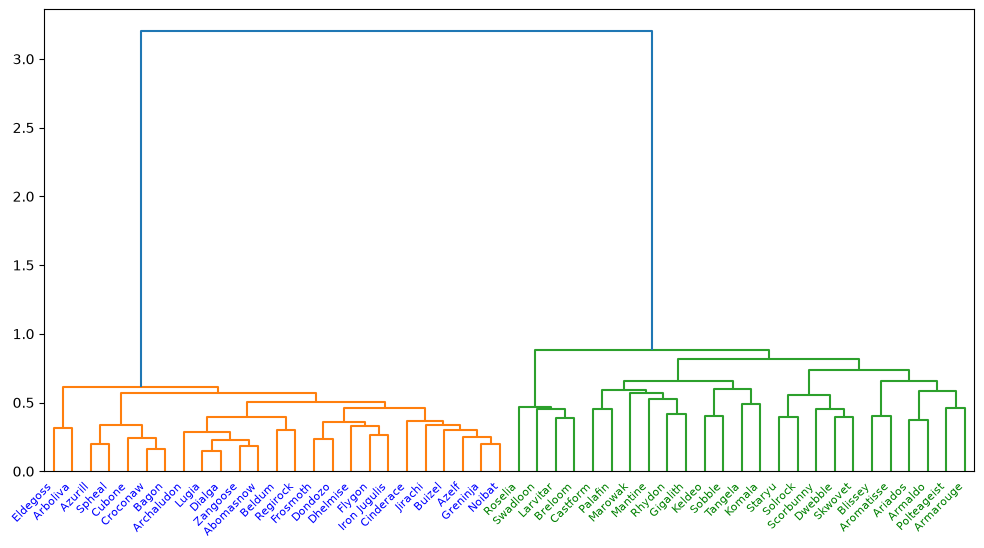

In [25]:
linkage_data = linkage(cond_distance_matrix, method='ward')

plt.figure(figsize=(12, 6))
ax = plt.subplot(111)
dendrogram(linkage_data, labels=df["name"])

for xtick in ax.get_xticklabels():
    label = xtick.get_text()
    if label not in image_dict:
        raise ValueError(f"Label {label} missing from dict")
    if image_dict[xtick.get_text()]:
        xtick.set_color('b')
    else:
        xtick.set_color('g')

plt.xticks(rotation=45, ha="right")


plt.savefig("test_cluster.png")
plt.show()